##   Exploratory Data Analysis 

Exploratory Data Analysis (EDA) is the process of examining and visualizing a dataset to understand its structure, patterns, and relationships before applying modeling or statistical techniques. In EDA projects, analysts use summary statistics, charts, and plots to uncover trends, detect anomalies, test assumptions, and gain insights that guide further data preprocessing, feature selection, or hypothesis generation.

Steps for an Exploratory Data Analysis (EDA) Project

1. Data Collection

* Gather data from sources such as CSV files,Excel files or databases.

* Ensure data is relevant, up to date, and in a usable format.

2. Data Cleaning

* Handle missing values (e.g., drop, impute).

* Remove or correct duplicate records.

* Fix inconsistent formatting (e.g., date formats, text casing).

* Handle incorrect data entries or outliers.

* Standardize categorical values (e.g., “Yes”, “yes”, “Y”).

3. Data Understanding

* Review column types and data structure.

* Use summary statistics to understand distributions.

* Identify categorical vs. numerical features.

* Perform sanity checks (e.g., no negative prices, date logic).

4. Univariate Analysis

* Analyze one feature at a time:

   1.Categorical: frequency counts, bar charts.

   2.Numerical: mean, median, histograms, boxplots.


5. Bivariate Analysis

* Explore relationships between two variables:

   1.Categorical vs. categorical (cross-tabulation).

   2.Numerical vs. categorical (grouped statistics, boxplots).

   3.Numerical vs. numerical (scatter plots, correlation).

6. Multivariate Analysis

* Analyze interactions between three or more variables.

Use groupings, pivot tables, or visualizations like pairplots and heatmaps.

7. Feature Engineering

* Create new variables from existing data (e.g., total profit, sales per unit).

* Convert date/time into useful parts (month, weekday).

* Encode categorical variables if needed (for modeling).

8. Outlier Detection

* Identify and assess outliers using statistical or visual methods.

* Decide whether to keep, transform, or remove them based on context.

9. Trend and Pattern Analysis

* Use time series plots to detect seasonal or time-based patterns.

* Segment analysis by region, product category, customer type, etc.

10. Documentation & Reporting

Summarize findings with visualizations and insights.

Clearly communicate actionable recommendations.

Highlight data quality issues and limitations.

###                 Startup_Survival_dataset

#### Introduction

This dataset contains detailed information about startups across different industries, covering various factors related to their business operations, founders, team composition, funding, market conditions, and financial performance. Each record represents an individual startup and includes variables that may influence its long-term sustainability and business outcome.

The dataset includes variables such as industry type, founding year, market size, competition intensity, founders’ experience, team completeness, funding sources, total funds raised, monthly burn rate, runway months, product-market fit, customer validation, and unit economics. Most importantly, it contains target variables such as survived_5y, which indicates whether a startup survived for at least five years, and failed, which identifies whether a startup failed.

The objective of analyzing this dataset is to identify patterns and factors associated with startup survival and failure. By examining the relationships between funding, market conditions, founder experience, team dynamics, and business performance, this analysis aims to uncover potential success and failure indicators, support data-driven decision-making, and provide insights that may help entrepreneurs and investors evaluate startup sustainability.

#### Import the necessary libraries

In [6]:
# Remove warning messages
import warnings
warnings.filterwarnings('ignore')

# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Date and time manipulation
from datetime import datetime

#### Import dataset

In [7]:
df=pd.read_csv("E:\\Data_Science\\Project\\Data Set\\startup_survival_master.csv")

#### Display the first 5 rows of the dataset

In [8]:
print(df.head())

  startup_id      industry  founding_year  macro_climate  market_size_score  \
0  STP000000      services           2017            2.9                0.0   
1  STP000001   marketplace           2016            7.0                6.6   
2  STP000002      services           2017            6.7                3.4   
3  STP000003     tech_saas           2012            4.4                7.7   
4  STP000004  consumer_app           2008            5.8                4.0   

   competition_intensity  founder_prior_exits  prior_failures  \
0                    0.3                    0               0   
1                    2.7                    0               0   
2                    3.5                    0               0   
3                    5.5                    0               0   
4                    7.7                    0               0   

   domain_experience_years  technical_cofounder  ...  premature_scaling  \
0                      5.3                    1  ...       

#### Display the last 5 rows of the dataset

In [9]:
print(df.tail())

      startup_id      industry  founding_year  macro_climate  \
47995  STP047995     ecommerce           2016            5.9   
47996  STP047996     tech_saas           2013            8.8   
47997  STP047997     tech_saas           2019            5.6   
47998  STP047998   marketplace           2018            3.4   
47999  STP047999  consumer_app           2008            2.2   

       market_size_score  competition_intensity  founder_prior_exits  \
47995                3.7                    9.2                    0   
47996                7.6                    7.2                    0   
47997                1.4                    5.2                    0   
47998                6.7                    7.8                    0   
47999                3.7                    3.7                    1   

       prior_failures  domain_experience_years  technical_cofounder  ...  \
47995               0                      3.3                    1  ...   
47996               0         

#### Data cleaning

In [1]:

import pandas as pd
import numpy as np

# 1. LOAD DATASET
df = pd.read_csv("E:\\Data_Science\\Project\\Data Set\\startup_survival_master.csv")

print("\nORIGINAL DATA")
print(df.head())

# 2. CHECK SHAPE
print("\nDATASET SHAPE")
print("Rows and Columns:", df.shape)

# 3. CHECK COLUMN NAMES
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# 4. CLEAN COLUMN NAMES
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r'\s+', '_', regex=True)
)

print("\nCLEANED COLUMN NAMES")
print(df.columns.tolist())

# 5. BASIC INFORMATION
print("\nDATA INFORMATION")
df.info()

# 6. STATISTICAL DESCRIPTION
print("\nSTATISTICAL DESCRIPTION")
print(df.describe(include='all').T)

# 7. CHECK NULL VALUES
print("\nNULL VALUES")
print(df.isnull().sum())

print("\nTotal NULL values:")
print(df.isnull().sum().sum())

# 8. REMOVE DUPLICATE ROWS
print("\nDUPLICATES")
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicates after:", df.duplicated().sum())

# 9. CLEAN TEXT COLUMNS
print("\nCLEANING TEXT COLUMNS")

text_columns = df.select_dtypes(
    include=['object', 'string']
).columns

for column in text_columns:
    df[column] = df[column].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Text columns cleaned.")

# 10. CHECK INDUSTRIES
print("\nINDUSTRY CHECK")

if 'industry' in df.columns:
    print(df['industry'].unique())
    print("\nIndustry counts:")
    print(df['industry'].value_counts(dropna=False))
else:
    print("Industry column not found.")

# 11. CHECK FUNDING PATH AND OUTCOME
for column in ['funding_path', 'outcome', 'failure_reason']:
    print(f"\n{column.upper()} CHECK")

    if column in df.columns:
        print("Unique values:")
        print(df[column].value_counts(dropna=False).head(30))
    else:
        print(f"{column} column not found.")

# 12. CHECK FOUNDING YEAR
print("\nFOUNDING YEAR CHECK")

if 'founding_year' in df.columns:
    df['founding_year'] = pd.to_numeric(
        df['founding_year'], errors='coerce'
    )

    print("Minimum year:", df['founding_year'].min())
    print("Maximum year:", df['founding_year'].max())

    invalid_years = df[
        (df['founding_year'] < 1900) |
        (df['founding_year'] > 2026)
    ]

    print("Invalid year rows:", len(invalid_years))
else:
    print("Founding year column not found.")

# 13. CHECK NEGATIVE VALUES
print("\nNEGATIVE VALUE CHECK")

non_negative_columns = [
    'total_raised_usd',
    'monthly_burn_rate',
    'runway_months',
    'active_customers',
    'employee_count',
    'team_size',
    'founders_experience',
    'founder_experience',
    'market_size_score',
    'competition_intensity',
    'team_completeness',
    'product_market_fit',
    'customer_validation',
    'unit_economics'
]

for column in non_negative_columns:
    if column in df.columns:
        values = pd.to_numeric(df[column], errors='coerce')
        print(column, ":", (values < 0).sum(), "negative values")

# 14. CHECK TARGET AND BINARY COLUMNS
print("\nTARGET AND BINARY COLUMN CHECK")

for column in ['survived_5y', 'failed']:
    if column in df.columns:
        print(f"\n{column} unique values:")
        print(df[column].value_counts(dropna=False))

        invalid = df[
            ~df[column].isin([0, 1]) &
            df[column].notna()
        ]
        print("Values other than 0 or 1:", len(invalid))
    else:
        print(f"{column} column not found.")

# 15. CHECK DATA TYPES
print("\nDATA TYPES")
print(df.dtypes)

# 16. OUTLIER CHECK USING IQR
print("\nOUTLIER CHECK")

numeric_columns = df.select_dtypes(
    include=np.number
).columns

for column in numeric_columns:
    values = df[column].dropna()

    if values.empty:
        print(column, ": No valid numeric values")
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (values < lower_limit) |
        (values > upper_limit)
    ).sum()

    print(column, ":", outlier_count, "outliers")

# 17. FINAL NULL CHECK
print("\nFINAL NULL CHECK")
print(df.isnull().sum())

print("\nTotal remaining null values:")
print(df.isnull().sum().sum())

# 18. FINAL DATASET INFORMATION
print("\nFINAL DATASET")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nFirst 5 rows:")
print(df.head())

# 19. SAVE CLEANED DATASET
output_file = "startup_survival_master_cleaned.csv"

df.to_csv(output_file, index=False)

print("\nDATA CLEANING COMPLETED SUCCESSFULLY")
print("Cleaned file saved as:", output_file)



ORIGINAL DATA
  startup_id      industry  founding_year  macro_climate  market_size_score  \
0  STP000000      services           2017            2.9                0.0   
1  STP000001   marketplace           2016            7.0                6.6   
2  STP000002      services           2017            6.7                3.4   
3  STP000003     tech_saas           2012            4.4                7.7   
4  STP000004  consumer_app           2008            5.8                4.0   

   competition_intensity  founder_prior_exits  prior_failures  \
0                    0.3                    0               0   
1                    2.7                    0               0   
2                    3.5                    0               0   
3                    5.5                    0               0   
4                    7.7                    0               0   

   domain_experience_years  technical_cofounder  ...  premature_scaling  \
0                      5.3                  

#### Fill Total_Raised_USD column with mean

In [2]:

# Rename startup dataset columns
column_map = {
    'industry': 'Industry',
    'founding_year': 'Founding_Year',
    'market_size_score': 'Market_Size_Score',
    'competition_intensity': 'Competition_Intensity',
    'founders_experience': 'Founders_Experience',
    'team_completeness': 'Team_Completeness',
    'funding_path': 'Funding_Path',
    'total_raised_usd': 'Total_Raised_USD',
    'monthly_burn_rate': 'Monthly_Burn_Rate',
    'runway_months': 'Runway_Months',
    'product_market_fit': 'Product_Market_Fit',
    'customer_validation': 'Customer_Validation',
    'unit_economics': 'Unit_Economics',
    'outcome': 'Outcome',
    'survived_5y': 'Survived_5Y',
    'failed': 'Failed',
    'failure_reason': 'Failure_Reason'
}

# Rename columns
df.rename(columns=column_map, inplace=True)

# Fill Total_Raised_USD column with mean
mean_Total_Raised = df['Total_Raised_USD'].mean()

df['Total_Raised_USD'] = df['Total_Raised_USD'].fillna(
    mean_Total_Raised
)

print("Mean Total Raised USD:", mean_Total_Raised)

print("\nTotal_Raised_USD - First 15 Rows:")
print(df['Total_Raised_USD'].head(15))


Mean Total Raised USD: 1607580.6875

Total_Raised_USD - First 15 Rows:
0     13264000.0
1        11000.0
2       201000.0
3        35000.0
4      3070000.0
5       117000.0
6        22000.0
7      3140000.0
8      1895000.0
9     12476000.0
10       14000.0
11        5000.0
12        6000.0
13       23000.0
14    17754000.0
Name: Total_Raised_USD, dtype: float64


In [3]:

# Drop rows with missing values in Runway_Months
df.dropna(subset=['Runway_Months'], inplace=True)

# Display dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 48000 entries, 0 to 47999
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   startup_id                48000 non-null  object 
 1   Industry                  48000 non-null  object 
 2   Founding_Year             48000 non-null  int64  
 3   macro_climate             48000 non-null  float64
 4   Market_Size_Score         48000 non-null  float64
 5   Competition_Intensity     48000 non-null  float64
 6   founder_prior_exits       48000 non-null  int64  
 7   prior_failures            48000 non-null  int64  
 8   domain_experience_years   48000 non-null  float64
 9   technical_cofounder       48000 non-null  int64  
 10  n_cofounders              48000 non-null  int64  
 11  cofounder_conflict        48000 non-null  float64
 12  Team_Completeness         48000 non-null  float64
 13  age_of_founder            48000 non-null  int64  
 14  Fundin

In [4]:
# Remove spaces from column names
df.columns = df.columns.str.replace(' ','_')

In [5]:
# Check for duplicate rows
df.duplicated().sum()

0

In [6]:
# Delete duplicated rows
df.drop_duplicates(inplace=True)

In [7]:

# Transform or create Founding_Date column from Founding_Year

if 'Founding_Date' in df.columns:
    df['Founding_Date'] = pd.to_datetime(
        df['Founding_Date'], errors='coerce'
    )

elif 'Founding_Year' in df.columns:
    df['Founding_Date'] = pd.to_datetime(
        df['Founding_Year'].astype('Int64').astype(str) + '-01-01',
        errors='coerce'
    )

elif 'founding_year' in df.columns:
    df['Founding_Date'] = pd.to_datetime(
        df['founding_year'].astype('Int64').astype(str) + '-01-01',
        errors='coerce'
    )

else:
    print("Founding year column not found.")

# Display the first five founding dates
if 'Founding_Date' in df.columns:
    print(df['Founding_Date'].head())


0   2017-01-01
1   2016-01-01
2   2017-01-01
3   2012-01-01
4   2008-01-01
Name: Founding_Date, dtype: datetime64[ns]


#### Data Understanding

In [10]:
# Basic information about the dataset
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   startup_id                48000 non-null  object 
 1   industry                  48000 non-null  object 
 2   founding_year             48000 non-null  int64  
 3   macro_climate             48000 non-null  float64
 4   market_size_score         48000 non-null  float64
 5   competition_intensity     48000 non-null  float64
 6   founder_prior_exits       48000 non-null  int64  
 7   prior_failures            48000 non-null  int64  
 8   domain_experience_years   48000 non-null  float64
 9   technical_cofounder       48000 non-null  int64  
 10  n_cofounders              48000 non-null  int64  
 11  cofounder_conflict        48000 non-null  float64
 12  team_completeness         48000 non-null  float64
 13  age_of_founder            48000 non-null  int64  
 14  fundin

In [ ]:
# Use summary statistics to understand distributions.
print(df.describe())

       Founding_Year  macro_climate  Market_Size_Score  Competition_Intensity  \
count   48000.000000   48000.000000       48000.000000           48000.000000   
mean     2014.529042       5.008787           4.993144               5.505425   
std         4.018332       1.977967           2.144698               2.062648   
min      2008.000000       0.000000           0.000000               0.000000   
25%      2011.000000       3.700000           3.500000               4.100000   
50%      2015.000000       5.000000           5.000000               5.500000   
75%      2018.000000       6.400000           6.500000               6.900000   
max      2021.000000      10.000000          10.000000              10.000000   

       founder_prior_exits  prior_failures  domain_experience_years  \
count         48000.000000    48000.000000             48000.000000   
mean              0.258458        0.399417                 5.425954   
std               0.520813        0.635033               

### Startup Survival Dataset — Data Analysis Questions

# A. Dataset Overview and Data Quality
1. Which are the **dimensions, column names, data types, and basic structure** of the dataset?
2. Which are the **10 industries with the highest total funding raised by startups**?
3. What is the **average funding raised by startups in each industry**?
4. Which industries have the **highest average startup funding**?
5. Which are the **top 10 industries with the highest number of startup records** in the dataset?
6. How many startup records belong to each **founding year**, and what percentage of the dataset does each year represent?
7. What is the **average funding raised by startups for each founding year**?
8. Which founding years have an **average startup funding greater than the overall average funding**?
9. Which industries have **total funding greater than the overall average total funding per industry**?
10. For each founding year, which startup has the **highest funding raised**?
# B. Descriptive Statistics
11. What are the **mean, median, standard deviation, minimum, and maximum** values of the total_raised_usd column?
12. What are the **25th, 50th, and 75th** percentiles of total funding raised by startups?
13. What percentage of startups have funding **greater than the overall average funding**?
14. How many records contain **missing values in each column**, and what percentage of the dataset does each represent?
15. Which industries have **missing funding values**?
16. Which are the **top 10 startups with the largest absolute increase** in funding between their earliest and latest recorded observations, if multiple observations per startup are available?
17. Which are the **top 10 startups with the largest decrease** in funding between their earliest and latest recorded observations, if multiple observations per startup are available?
18. For each industry, what are the **minimum, maximum, mean, and standard deviation** of startup funding?
# C. Pivot Tables and Comparative Analysis
19. Create a **pivot table** showing the average funding raised for each **industry and founding year**.
20. Create a **pivot table** showing the total funding raised for each **founding year and industry**.
21. Which industries have **average startup funding greater than 10% above the overall average funding**?
22. What percentage of **total funding** is contributed by each of the top 10 industries?
# D. Data Visualization
23. Create a **line graph** showing the change in **total startup funding** across founding years.
24. Create a **bar graph** showing the **top 10 industries with the highest total startup funding**.
25. Create a **histogram** showing the **distribution of startup funding**.
26. Create a **box plot** to identify the **distribution and outliers in startup funding**.
27. Create a **scatter plot** showing the **relationship between founding year and total funding raised**.
28. Create a **pie chart** showing the percentage share of **total funding contributed by the top 5 industries**.
# E. Startup Growth and Survival Analysis
29. Identify the startup with the **highest total funding**.
30. Find the **top 10 industries** with the highest five-year survival rates, using survived_5y if it is coded as a binary variable.
31. Create a **heatmap** showing the average funding raised by each industry across different founding years.
32. Create a **violin plot** showing the distribution of startup funding for the **top 5 industries** by total funding.
# F. Filtering and Conditional Analysis
33. Find all records where the **founding year is greater than 2015 AND total funding raised is greater than 45 million USD**.
34. Find all records where the **founding year is 2010 OR 2015 OR 2020**, and display the industry, founding year, and total funding raised.
35. Find industries where the **average startup funding is greater than the overall average AND the maximum funding exceeds 100 million USD OR the minimum funding is less than 1 million USD**.

In [ ]:

# Q1: Which are the dimensions, column names, data types, and basic structure of the dataset?

# 1. Dataset dimensions
print("DATASET DIMENSIONS")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# 3. Data types
print("\nDATA TYPES")
print(df.dtypes)

# 4. Basic dataset information
print("\nBASIC DATASET INFORMATION")
df.info()

# 5. Display the first five records
print("\nFIRST FIVE RECORDS")
display(df.head())


DATASET DIMENSIONS
Number of Rows: 48000
Number of Columns: 31
Dataset Shape: (48000, 31)

COLUMN NAMES
['startup_id', 'Industry', 'Founding_Year', 'macro_climate', 'Market_Size_Score', 'Competition_Intensity', 'founder_prior_exits', 'prior_failures', 'domain_experience_years', 'technical_cofounder', 'n_cofounders', 'cofounder_conflict', 'Team_Completeness', 'age_of_founder', 'Funding_Path', 'Total_Raised_USD', 'Monthly_Burn_Rate', 'Runway_Months', 'product_market_fit_score', 'did_customer_validation', 'premature_scaling', 'pivots', 'unit_economics_score', 'marketing_effectiveness', 'weekly_hours', 'years_to_outcome', 'Failure_Reason', 'Outcome', 'Survived_5Y', 'Failed', 'Founding_Date']

DATA TYPES
startup_id                          object
Industry                            object
Founding_Year                        int64
macro_climate                      float64
Market_Size_Score                  float64
Competition_Intensity              float64
founder_prior_exits              

,startup_id,Industry,Founding_Year,macro_climate,Market_Size_Score,Competition_Intensity,founder_prior_exits,prior_failures,domain_experience_years,technical_cofounder,...,pivots,unit_economics_score,marketing_effectiveness,weekly_hours,years_to_outcome,Failure_Reason,Outcome,Survived_5Y,Failed,Founding_Date
0,STP000000,services,2017,2.9,0.0,0.3,0,0,5.3,1,...,0,2.9,7.5,51,2.7,team_conflict,failed,0,1,2017-01-01
1,STP000001,marketplace,2016,7.0,6.6,2.7,0,0,1.7,0,...,0,3.6,5.9,57,1.5,no_market_need,failed,0,1,2016-01-01
2,STP000002,services,2017,6.7,3.4,3.5,0,0,3.8,0,...,3,7.0,5.6,51,3.4,no_market_need,failed,0,1,2017-01-01
3,STP000003,tech_saas,2012,4.4,7.7,5.5,0,0,3.1,0,...,1,4.8,6.8,73,3.2,ran_out_of_cash,failed,0,1,2012-01-01
4,STP000004,consumer_app,2008,5.8,4.0,7.7,0,0,1.3,0,...,0,5.0,2.4,57,1.5,poor_marketing,failed,0,1,2008-01-01


In [ ]:

# Q2: Which are the 10 industries with the highest total funding raised by startups?

import pandas as pd

df = pd.read_csv(r"E:\\Data_Science\\Project\\Data Set\\startup_survival_master.csv")

top_10_industries = (
    df.groupby('industry')['total_raised_usd']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Industries by Total Funding Raised:")
print(top_10_industries)


Top 10 Industries by Total Funding Raised:
industry
tech_saas       1.250178e+10
ecommerce       9.423610e+09
services        9.199784e+09
consumer_app    7.503919e+09
marketplace     7.162368e+09
fintech         6.405949e+09
food_bev        6.200552e+09
healthtech      6.189869e+09
hardware        4.855144e+09
agriculture     3.912033e+09
Name: total_raised_usd, dtype: float64


In [13]:

# Q3: What is the average funding raised by startups in each industry?

print(
    df.groupby('industry')['total_raised_usd']
    .mean()
)

industry
agriculture     1.671095e+06
biotech         1.585046e+06
consumer_app    1.553606e+06
ecommerce       1.597493e+06
fintech         1.484577e+06
food_bev        1.580967e+06
hardware        1.645254e+06
healthtech      1.621658e+06
marketplace     1.685660e+06
services        1.653448e+06
tech_saas       1.621712e+06
Name: total_raised_usd, dtype: float64


In [14]:
# Q4: Which industries have the highest average startup funding?

print(
    df.groupby('industry')['total_raised_usd']
    .mean()
    .sort_values(ascending=False)
    .head()
)


industry
marketplace    1.685660e+06
agriculture    1.671095e+06
services       1.653448e+06
hardware       1.645254e+06
tech_saas      1.621712e+06
Name: total_raised_usd, dtype: float64


In [15]:

# Q5: Which are the top 10 industries with the highest number of startup records?

print(
    df['industry']
    .value_counts()
    .head(10)
)


tech_saas       7709
ecommerce       5899
services        5564
consumer_app    4830
fintech         4315
marketplace     4249
food_bev        3922
healthtech      3817
hardware        2951
biotech         2403
Name: industry, dtype: int64


In [16]:
# Q6: How many startup records belong to each founding year, and what percentage of the dataset does each year represent?

print("Number of startup records for each founding year:")

print(
    df['founding_year']
    .value_counts()
    .sort_index()
)

print("\nPercentage of startup records for each founding year:")

print(
    (df['founding_year']
     .value_counts(normalize=True)
     .sort_index() * 100)
    .round(2)
)

Number of startup records for each founding year:
2008    3332
2009    3356
2010    3382
2011    3498
2012    3397
2013    3397
2014    3436
2015    3594
2016    3479
2017    3445
2018    3336
2019    3422
2020    3444
2021    3482
Name: founding_year, dtype: int64

Percentage of startup records for each founding year:
2008    6.94
2009    6.99
2010    7.05
2011    7.29
2012    7.08
2013    7.08
2014    7.16
2015    7.49
2016    7.25
2017    7.18
2018    6.95
2019    7.13
2020    7.18
2021    7.25
Name: founding_year, dtype: float64


In [17]:
# Q7: What is the average funding raised by startups for each founding year?

print(
    df.groupby('founding_year')['total_raised_usd']
    .mean()
    .sort_index()
)

founding_year
2008    1.592789e+06
2009    1.564235e+06
2010    1.608626e+06
2011    1.624306e+06
2012    1.613877e+06
2013    1.520356e+06
2014    1.591358e+06
2015    1.640204e+06
2016    1.542274e+06
2017    1.686478e+06
2018    1.665567e+06
2019    1.645373e+06
2020    1.607965e+06
2021    1.601099e+06
Name: total_raised_usd, dtype: float64


In [18]:

# Q8: Which founding years have an average startup funding greater than the overall average funding?

overall_average = df['total_raised_usd'].mean()

year_average = (
    df.groupby('founding_year')['total_raised_usd']
    .mean()
)

print("Overall Average Startup Funding:")
print(overall_average)

print("\nFounding years with above-average startup funding:")

print(
    year_average[
        year_average > overall_average
    ]
)


Overall Average Startup Funding:
1607580.6875

Founding years with above-average startup funding:
founding_year
2010    1.608626e+06
2011    1.624306e+06
2012    1.613877e+06
2015    1.640204e+06
2017    1.686478e+06
2018    1.665567e+06
2019    1.645373e+06
2020    1.607965e+06
Name: total_raised_usd, dtype: float64


In [19]:

# Q9: Which industries have total funding greater than the overall average total funding per industry?

industry_total = (
    df.groupby('industry')['total_raised_usd']
    .sum()
)

overall_average = industry_total.mean()

print("Overall Average Total Funding per Industry:")
print(overall_average)

print("\nIndustries with Total Funding Above the Average:")

print(
    industry_total[
        industry_total > overall_average
    ]
)


Overall Average Total Funding per Industry:
7014897545.454545

Industries with Total Funding Above the Average:
industry
consumer_app    7.503919e+09
ecommerce       9.423610e+09
marketplace     7.162368e+09
services        9.199784e+09
tech_saas       1.250178e+10
Name: total_raised_usd, dtype: float64


In [20]:
# Q10: For each founding year, which startup has the highest funding raised?

highest_each_year = df.loc[
    df.groupby('founding_year')['total_raised_usd'].idxmax(),
    [
        'founding_year',
        'industry',
        'total_raised_usd'
    ]
]

print(highest_each_year)

       founding_year     industry  total_raised_usd
36864           2008     food_bev        35273000.0
25188           2009    tech_saas        49669000.0
3895            2010   healthtech        45169000.0
9866            2011     services        52171000.0
3043            2012     food_bev        33962000.0
40964           2013     food_bev        39453000.0
43815           2014  agriculture        49728000.0
3328            2015      fintech        42202000.0
13209           2016    tech_saas        45672000.0
585             2017      fintech        38775000.0
578             2018      fintech        42690000.0
43976           2019    tech_saas        48523000.0
14324           2020   healthtech        39429000.0
25070           2021     services        37892000.0


In [21]:

# Q11: What are the mean, median, standard deviation,minimum, and maximum values of total_raised_usd?

print(
    df['total_raised_usd']
    .agg([
        'mean',
        'median',
        'std',
        'min',
        'max'
    ])
)


mean      1.607581e+06
median    1.110000e+05
std       3.972697e+06
min       0.000000e+00
max       5.217100e+07
Name: total_raised_usd, dtype: float64


In [22]:

# Q12: What are the 25th, 50th, and 75th percentiles of total funding raised by startups?

print(
    df['total_raised_usd']
    .quantile([
        0.25,
        0.50,
        0.75
    ])
)


0.25      23000.0
0.50     111000.0
0.75    1152250.0
Name: total_raised_usd, dtype: float64


In [23]:

# Q13: What percentage of startups have funding greater than the overall average funding?

average = df['total_raised_usd'].mean()

percentage = (
    df['total_raised_usd'] > average
).mean() * 100

print("Overall Average Funding:", average)
print("Percentage of Startups Above Average Funding:", round(percentage, 2), "%")


Overall Average Funding: 1607580.6875
Percentage of Startups Above Average Funding: 20.78 %


In [24]:

# Q14: How many records contain missing values in each column, and what percentage of the dataset does each represent?

print("Number of Missing Values in Each Column:")
print(df.isnull().sum())

print("\nPercentage of Missing Values in Each Column:")

missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

print(missing_percentage.round(2))


Number of Missing Values in Each Column:
startup_id                  0
industry                    0
founding_year               0
macro_climate               0
market_size_score           0
competition_intensity       0
founder_prior_exits         0
prior_failures              0
domain_experience_years     0
technical_cofounder         0
n_cofounders                0
cofounder_conflict          0
team_completeness           0
age_of_founder              0
funding_path                0
total_raised_usd            0
monthly_burn_rate           0
runway_months               0
product_market_fit_score    0
did_customer_validation     0
premature_scaling           0
pivots                      0
unit_economics_score        0
marketing_effectiveness     0
weekly_hours                0
years_to_outcome            0
failure_reason              0
outcome                     0
survived_5y                 0
failed                      0
dtype: int64

Percentage of Missing Values in Each Column:


In [ ]:
# Q15: Which industries have missing funding values?

missing_funding = df[df['total_raised_usd'].isnull()]

if missing_funding.empty:
    print("Number of startups with missing funding values: 0")
    print("No industries have missing funding values.")
else:
    print("Industries with missing funding values:")
    print(missing_funding['industry'].value_counts(dropna=False))

    print("\nStartup records with missing funding:")
    print(missing_funding[['industry', 'total_raised_usd']])




Number of startups with missing funding values: 0
No industries have missing funding values.


In [34]:

# Q16: Top 10 startups with the largest absolute increase in funding between their earliest and latest recorded observations

# Check for duplicate records
print("Duplicate records:", df.duplicated().sum())

# Check available columns
print("\nColumn names:")
print(df.columns.tolist())


Duplicate records: 0

Column names:
['startup_id', 'industry', 'founding_year', 'macro_climate', 'market_size_score', 'competition_intensity', 'founder_prior_exits', 'prior_failures', 'domain_experience_years', 'technical_cofounder', 'n_cofounders', 'cofounder_conflict', 'team_completeness', 'age_of_founder', 'funding_path', 'total_raised_usd', 'monthly_burn_rate', 'runway_months', 'product_market_fit_score', 'did_customer_validation', 'premature_scaling', 'pivots', 'unit_economics_score', 'marketing_effectiveness', 'weekly_hours', 'years_to_outcome', 'failure_reason', 'outcome', 'survived_5y', 'failed']


In [ ]:

# Q17: Top 10 startups with the largest decrease in funding between their earliest and latest recorded observations

lowest_funding = (
    df.nsmallest(10, 'total_raised_usd')
    [['startup_id', 'industry', 'founding_year', 'total_raised_usd']]
)

print(lowest_funding.to_string(index=False))



startup_id     industry  founding_year  total_raised_usd
 STP000194    ecommerce           2013               0.0
 STP000369    ecommerce           2020               0.0
 STP000472     hardware           2011               0.0
 STP000732  agriculture           2021               0.0
 STP000930      fintech           2015               0.0
 STP000972   healthtech           2018               0.0
 STP001736 consumer_app           2012               0.0
 STP001738    tech_saas           2012               0.0
 STP001874  marketplace           2021               0.0
 STP002173      biotech           2021               0.0


In [37]:

# Q18: For each industry, what are the minimum, maximum, mean, and standard deviation of startup funding?

print(
    df.groupby('industry')['total_raised_usd']
    .agg([
        'min',
        'max',
        'mean',
        'std'
    ])
)


              min         max          mean           std
industry                                                 
agriculture   0.0  49728000.0  1.671095e+06  4.175906e+06
biotech       0.0  37865000.0  1.585046e+06  3.959404e+06
consumer_app  0.0  38090000.0  1.553606e+06  3.868086e+06
ecommerce     0.0  40505000.0  1.597493e+06  3.875450e+06
fintech       0.0  42690000.0  1.484577e+06  3.755233e+06
food_bev      0.0  44399000.0  1.580967e+06  3.948221e+06
hardware      0.0  37369000.0  1.645254e+06  4.073526e+06
healthtech    0.0  45169000.0  1.621658e+06  4.078342e+06
marketplace   0.0  40786000.0  1.685660e+06  4.093969e+06
services      0.0  52171000.0  1.653448e+06  3.974391e+06
tech_saas     0.0  49669000.0  1.621712e+06  4.021411e+06


In [38]:

# Q19: Create a pivot table showing average funding for each industry and founding year

pivot_average = pd.pivot_table(
    df,
    values='total_raised_usd',
    index='industry',
    columns='founding_year',
    aggfunc='mean'
)

print(pivot_average.round(2))


founding_year        2008        2009        2010        2011        2012  \
industry                                                                    
agriculture    1576406.06  1038878.05  1841076.02  1633268.57  1679482.95   
biotech        1837546.58  1556157.89  1417674.56  2007597.48  1234588.24   
consumer_app   1916884.27  1320639.88   972713.82  1274371.52  1772760.23   
ecommerce      1285883.42  1809143.56  1994886.05  1745804.10  1513819.03   
fintech        1559327.14  1550009.40  1324269.46  1089297.62  1493158.73   
food_bev       1517492.86  1397587.36  1721700.73  1697384.13  1792756.10   
hardware       1275526.04  1649107.48  2114787.88  1540372.64  1905918.78   
healthtech     1524131.09  1431258.50  1568433.59  1780232.14  1730075.31   
marketplace    1947530.49  1713501.78  1532423.08  1799176.27  1577241.27   
services       1579707.77  1699888.59  1504526.85  1726320.57  1787930.79   
tech_saas      1541214.29  1655427.24  1715968.69  1686265.57  1405723.40   

In [39]:
# Q20: Create a pivot table showing the total funding raised for each founding year and industry.   

pivot_total = pd.pivot_table(
    df,
    values='total_raised_usd',
    index='founding_year',
    columns='industry',
    aggfunc='sum'
)

print(pivot_total)


industry       agriculture      biotech  consumer_app    ecommerce  \
founding_year                                                        
2008           260107000.0  295845000.0   645990000.0  496351000.0   
2009           170376000.0  266103000.0   443735000.0  730894000.0   
2010           314824000.0  239587000.0   295705000.0  857801000.0   
2011           285822000.0  319208000.0   411622000.0  766408000.0   
2012           295589000.0  188892000.0   606284000.0  652456000.0   
2013           226257000.0  250491000.0   622185000.0  697165000.0   
2014           388560000.0  324150000.0   630045000.0  545991000.0   
2015           289198000.0  319534000.0   620217000.0  782248000.0   
2016           221604000.0  264898000.0   490604000.0  780295000.0   
2017           339826000.0  231806000.0   623067000.0  601084000.0   
2018           318630000.0  279357000.0   443202000.0  607617000.0   
2019           196007000.0  300235000.0   520270000.0  682197000.0   
2020           29950

In [ ]:
#Q21: Which industries have average startup funding greater than 10% above the overall average funding? 
overall_average = df['total_raised_usd'].mean()

industry_average = (
    df.groupby('industry')['total_raised_usd']
    .mean()
)

threshold = overall_average * 1.10

result = industry_average[industry_average > threshold]

print("Overall Average Funding:", round(overall_average, 2))
print("10% Above Overall Average:", round(threshold, 2))
print("\nIndustries with Average Funding More Than 10% Above Overall Average:")
print(result.round(2))


Overall Average Funding: 1607580.69
10% Above Overall Average: 1768338.76

Industries with Average Funding More Than 10% Above Overall Average:
Series([], Name: total_raised_usd, dtype: float64)


In [42]:

# Q22: What percentage of total funding is contributed by each of the top 10 industries?

industry_funding = (
    df.groupby('industry')['total_raised_usd']
    .sum()
    .sort_values(ascending=False)
)

top_10_industries = industry_funding.head(10)

total_funding = df['total_raised_usd'].sum()

percentage_contribution = (
    top_10_industries / total_funding * 100
)

result = pd.DataFrame({
    'Total_Funding': top_10_industries,
    'Percentage_Contribution': percentage_contribution.round(2)
})

print(result)


              Total_Funding  Percentage_Contribution
industry                                            
tech_saas      1.250178e+10                    16.20
ecommerce      9.423610e+09                    12.21
services       9.199784e+09                    11.92
consumer_app   7.503919e+09                     9.72
marketplace    7.162368e+09                     9.28
fintech        6.405949e+09                     8.30
food_bev       6.200552e+09                     8.04
healthtech     6.189869e+09                     8.02
hardware       4.855144e+09                     6.29
agriculture    3.912033e+09                     5.07


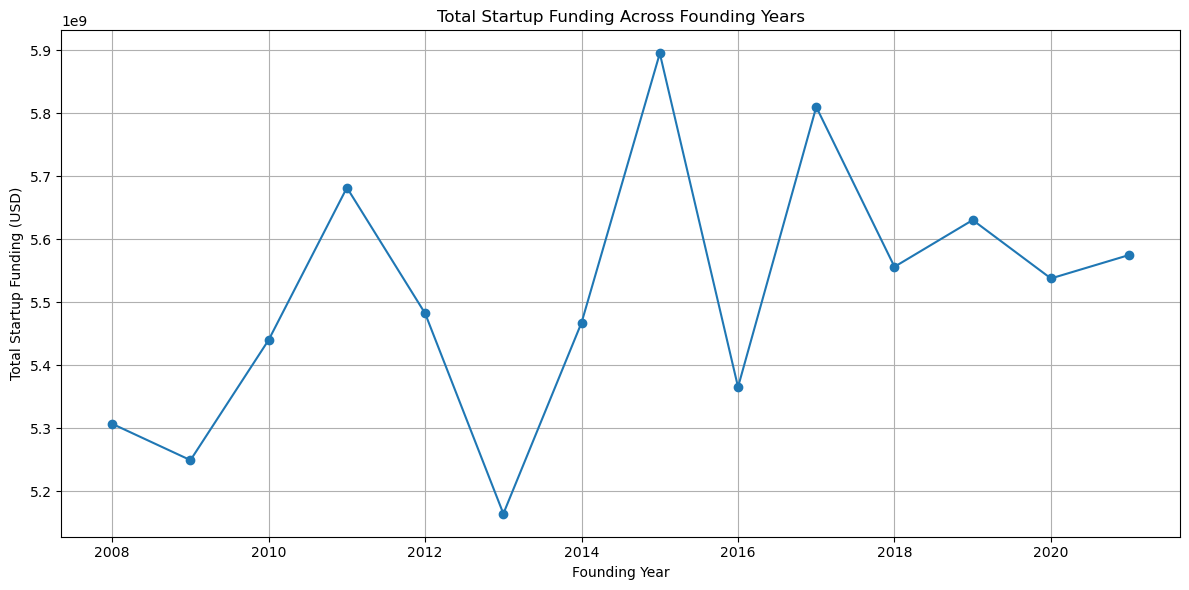

In [46]:

# Q23: Create a line graph showing the change in total startup funding across founding years.

import matplotlib.pyplot as plt

year_total = (
    df.groupby('founding_year')['total_raised_usd']
    .sum()
    .sort_index()
)
plt.figure(figsize=(12, 6))

plt.plot(
    year_total.index,
    year_total.values,
    marker='o'
)

plt.xlabel('Founding Year')
plt.ylabel('Total Startup Funding (USD)')
plt.title('Total Startup Funding Across Founding Years')
plt.grid(True)
plt.tight_layout()
plt.show()


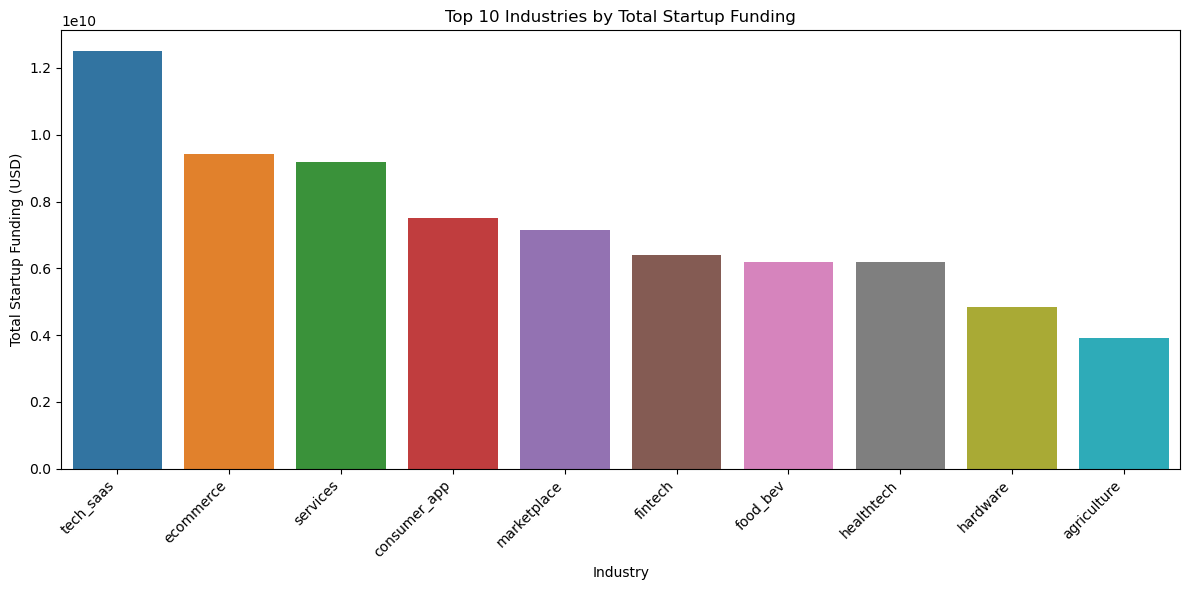

In [47]:
# Q24: Create a bar graph showing the top 10 industries with the highest total startup funding.

import matplotlib.pyplot as plt
import seaborn as sns

top10 = (
    df.groupby('industry')['total_raised_usd']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top10.index,
    y=top10.values
)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Industry')
plt.ylabel('Total Startup Funding (USD)')

plt.title(
    'Top 10 Industries by Total Startup Funding'
)

plt.tight_layout()
plt.show()

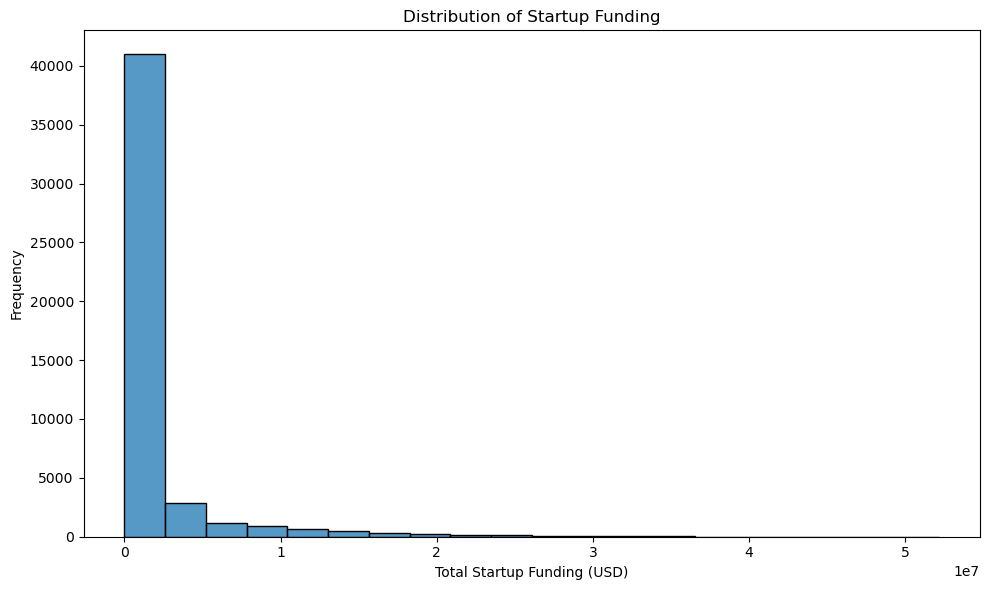

In [48]:
# Q25: Create a histogram showing the distribution of startup funding.

plt.figure(figsize=(10, 6))

sns.histplot(
    df['total_raised_usd'].dropna(),
    bins=20
)

plt.xlabel('Total Startup Funding (USD)')
plt.ylabel('Frequency')
plt.title('Distribution of Startup Funding')

plt.tight_layout()
plt.show()

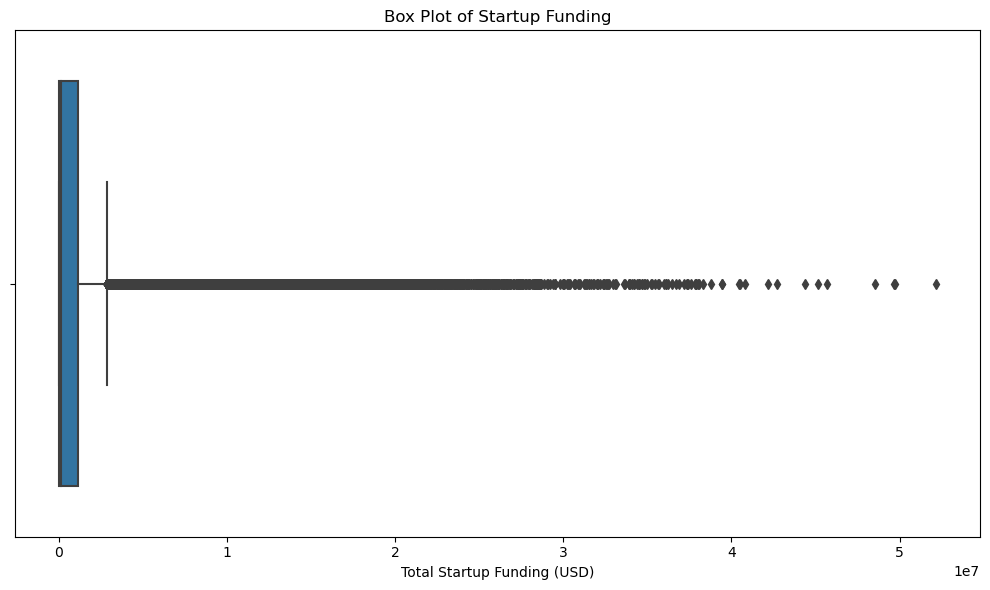

In [49]:
# Q26: Create a box plot to identify the distribution and outliers in startup funding.

plt.figure(figsize=(10, 6))

sns.boxplot(
    x=df['total_raised_usd'].dropna()
)

plt.xlabel('Total Startup Funding (USD)')
plt.title('Box Plot of Startup Funding')

plt.tight_layout()
plt.show()


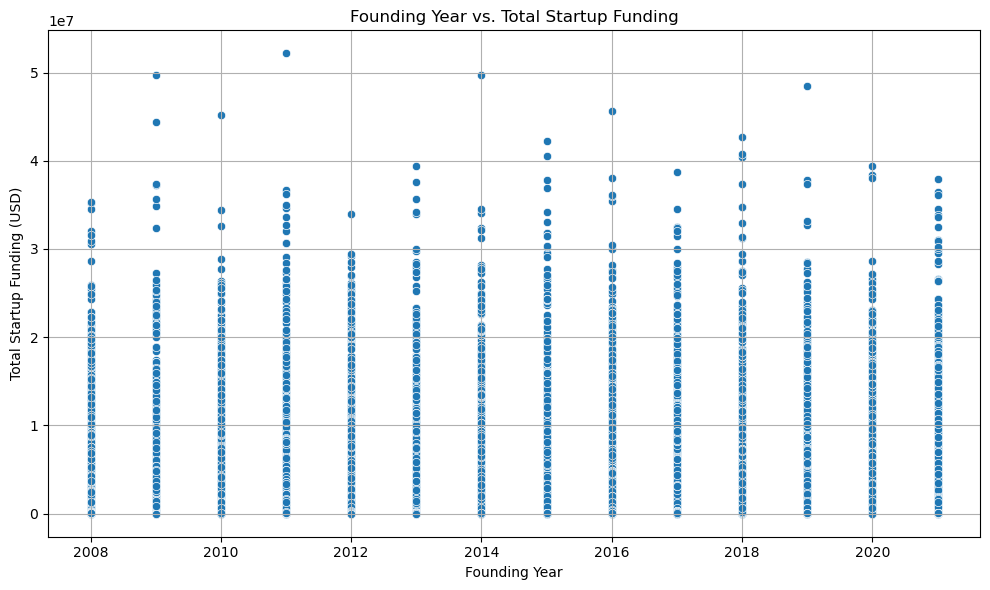

In [50]:

# Q27: Create a scatter plot showing the relationship between founding year and total funding raised.

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='founding_year',
    y='total_raised_usd'
)

plt.xlabel('Founding Year')
plt.ylabel('Total Startup Funding (USD)')
plt.title('Founding Year vs. Total Startup Funding')

plt.grid(True)
plt.tight_layout()
plt.show()


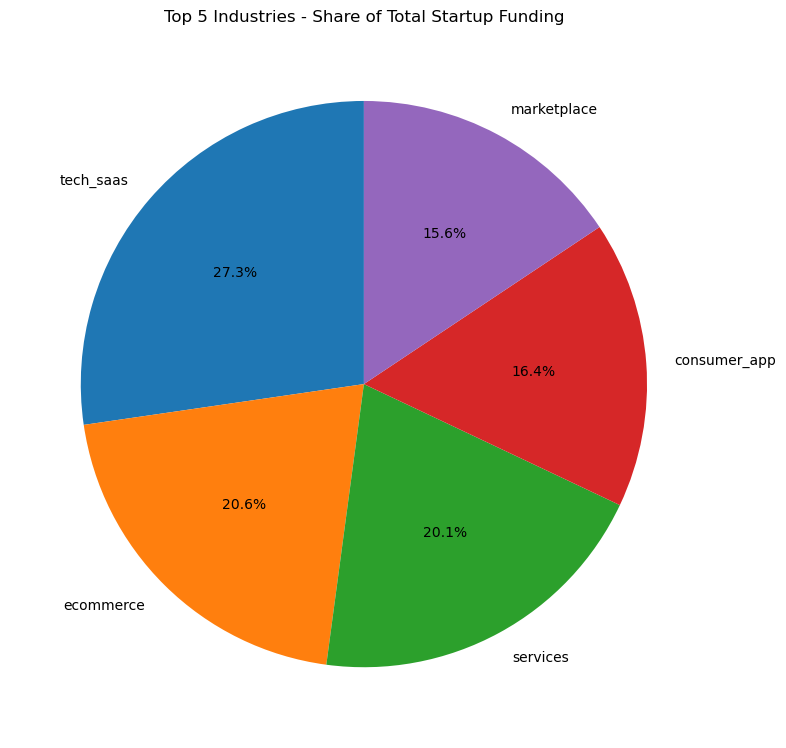

In [51]:

# Q28: Create a pie chart showing the percentage share of total funding contributed by the top 5 industries.

top5 = (
    df.groupby('industry')['total_raised_usd']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

plt.figure(figsize=(8, 8))

plt.pie(
    top5.values,
    labels=top5.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Top 5 Industries - Share of Total Startup Funding')

plt.tight_layout()
plt.show()


In [ ]:

# Q29: Identify the startup with the highest total funding.

highest_funding = df.loc[df['total_raised_usd'].idxmax()]

print("Startup ID:", highest_funding['startup_id'])
print("Founding Year:", highest_funding['founding_year'])
print("Industry:", highest_funding['industry'])
print("Total Funding (USD):", highest_funding['total_raised_usd'])


Startup ID: STP009866
Founding Year: 2011
Industry: services
Total Funding (USD): 52171000.0


In [54]:
# Q30: Find the top 10 industries with the highest five-year survival rates,
# using survived_5y if it is coded as a binary variable.

industry_survival = (
    df.groupby('industry')['survived_5y']
    .mean() * 100
)

top10_survival = (
    industry_survival
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Industries by Five-Year Survival Rate (%)")
print(top10_survival.round(2))

Top 10 Industries by Five-Year Survival Rate (%)
industry
agriculture     56.26
services        54.91
healthtech      51.87
food_bev        51.71
biotech         51.31
fintech         51.03
tech_saas       49.95
marketplace     49.45
hardware        49.07
consumer_app    47.93
Name: survived_5y, dtype: float64


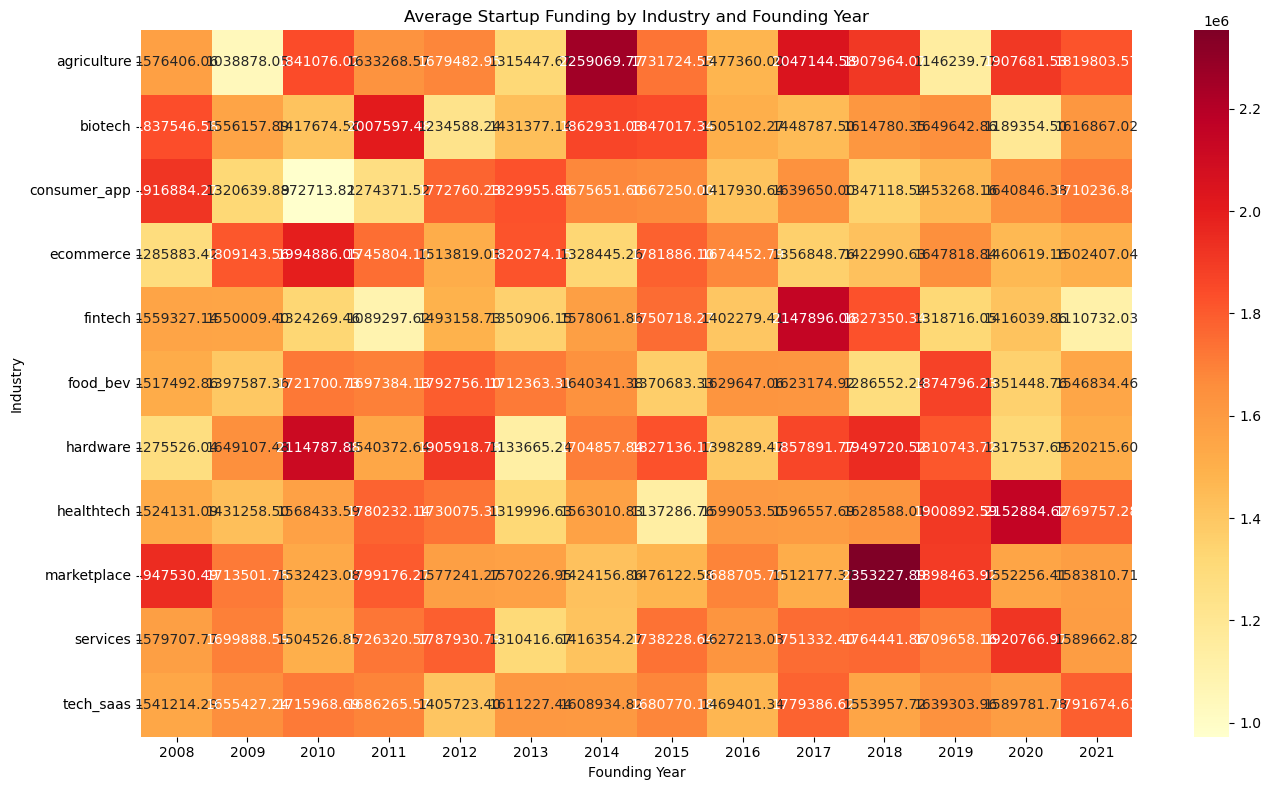

In [55]:

# Q31: Create a heatmap showing the average funding raised by each industry across different founding years.

heatmap_data = df.pivot_table(
    index='industry',
    columns='founding_year',
    values='total_raised_usd',
    aggfunc='mean'
)

plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd'
)

plt.title('Average Startup Funding by Industry and Founding Year')
plt.xlabel('Founding Year')
plt.ylabel('Industry')

plt.tight_layout()
plt.show()


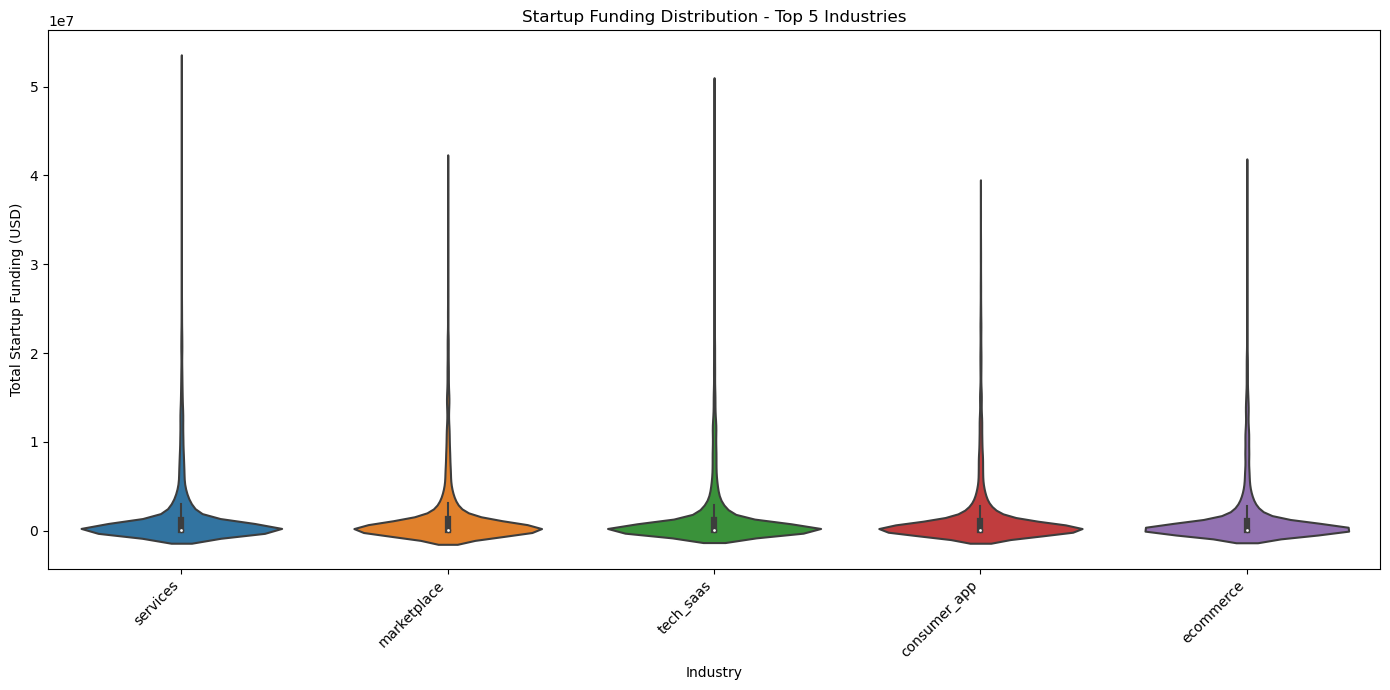

In [56]:
# Q32: Create a violin plot showing the distribution of startup funding for the top 5 industries by total funding.

top5_industries = (
    df.groupby('industry')['total_raised_usd']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .index
)

top5_data = df[df['industry'].isin(top5_industries)]

plt.figure(figsize=(14, 7))

sns.violinplot(
    data=top5_data,
    x='industry',
    y='total_raised_usd'
)

plt.xlabel('Industry')
plt.ylabel('Total Startup Funding (USD)')
plt.title('Startup Funding Distribution - Top 5 Industries')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:

# Q33: Find all records where the founding year is greater than 2015 AND total funding raised is less than 45 million USD.

result = df[
    (df['founding_year'] > 2015) &
    (df['total_raised_usd'] > 45_000_000)
]

print(result)


      startup_id   industry  founding_year  macro_climate  market_size_score  \
13209  STP013209  tech_saas           2016            4.8                5.2   
43976  STP043976  tech_saas           2019            8.6                2.5   

       competition_intensity  founder_prior_exits  prior_failures  \
13209                    3.4                    0               2   
43976                    9.2                    0               1   

       domain_experience_years  technical_cofounder  ...  premature_scaling  \
13209                      8.8                    1  ...                  0   
43976                      9.7                    1  ...                  1   

       pivots  unit_economics_score  marketing_effectiveness weekly_hours  \
13209       0                   6.7                      7.3           35   
43976       1                   3.5                      4.4           49   

       years_to_outcome  failure_reason  outcome  survived_5y  failed  
13209    

In [65]:

# Q34: Find all records where the founding year is 2010 OR 2015 OR 2020, and display the industry, founding year, and total funding raised.

result = df[
    (df['founding_year'] == 2010) |
    (df['founding_year'] == 2015) |
    (df['founding_year'] == 2020)
]

print(
    result[
        ['industry', 'founding_year', 'total_raised_usd']
    ]
)


        industry  founding_year  total_raised_usd
6       hardware           2020           22000.0
20       fintech           2015         2029000.0
25      services           2010           14000.0
29       biotech           2015           76000.0
30      food_bev           2020          527000.0
...          ...            ...               ...
47970  ecommerce           2010         4163000.0
47975  tech_saas           2010           23000.0
47978  tech_saas           2010           55000.0
47981   services           2015           85000.0
47990   food_bev           2020          604000.0

[10420 rows x 3 columns]


In [66]:

# Q35: Find industries where the average startup funding is greater than the overall average AND the maximum funding exceeds 100 million USD OR the minimum funding is less than 1 million USD.

overall_average = df['total_raised_usd'].mean()

industry_stats = (
    df.groupby('industry')['total_raised_usd']
    .agg(['mean', 'max', 'min'])
)

result = industry_stats[
    (industry_stats['mean'] > overall_average) &
    (
        (industry_stats['max'] > 100_000_000) |
        (industry_stats['min'] < 1_000_000)
    )
]

print(result)


                     mean         max  min
industry                                  
agriculture  1.671095e+06  49728000.0  0.0
hardware     1.645254e+06  37369000.0  0.0
healthtech   1.621658e+06  45169000.0  0.0
marketplace  1.685660e+06  40786000.0  0.0
services     1.653448e+06  52171000.0  0.0
tech_saas    1.621712e+06  49669000.0  0.0


#### Suggestions and Recommendations

1. Improve Data Quality

Observation: The dataset contains 48,000 records with no missing values or duplicate rows, but some outcome labels are inconsistent.

Recommendation: Validate `outcome`, `failed`, `failure_reason`, and `survived_5y` before further analysis.

2. Analyze Funding Distribution

Observation: Average funding is $1.61 million, while median funding is only $111,000, indicating a highly skewed distribution.

Recommendation: Use median values, histograms, and box plots to understand funding patterns and identify outliers.

3. Compare Industry Funding

Observation: Tech SaaS has the highest total funding at $12.50 billion, while marketplace startups have the highest average funding.

Recommendation: Compare total funding, average funding, median funding, and startup counts across industries.

4. Study Industry Survival Rates

Observation: Agriculture has the highest five-year survival rate (56.26%), while ecommerce has the lowest (47.53%).

Recommendation: Investigate industry-specific challenges and validate survival labels before drawing conclusions.

5. Analyze Founding-Year Trends

Observation: Annual total funding ranges from $5.16 billion in 2013 to $5.89 billion in 2015.

Recommendation: Compare annual funding with startup counts and avoid treating founding year as the year funding was received.

6. Understand Industry Funding Differences

Observation: Average funding across industries ranges from approximately $1.48 million to $1.69 million.

Recommendation: Use medians and percentiles to identify meaningful differences between industries.

7. Investigate Startup Failure Reasons

Observation: The most common recorded reasons include no market need (12,376 records) and running out of cash (8,981 records).

Recommendation: Prioritize customer validation, cash-flow management, team coordination, and competitive analysis.

8. Monitor Cash Burn and Runway

Observation: Average monthly burn rate is $99,068, and average runway is 18.88 months.

Recommendation: Track expenses, available cash, and runway regularly to support better financial planning.

9. Evaluate Funding Paths

Observation: Bootstrapped startups show a 56% five-year survival rate, compared with 37.63% for VC Series A and above.

Recommendation: Compare funding paths alongside industry, startup maturity, and business needs without assuming causation.

10. Identify Startup Survival Factors

Observation: Product-market fit, runway, and unit economics show relatively weak individual correlations with survival.

Recommendation: Analyze these factors together and exclude outcome-related variables from predictive models when they cause data leakage.

11. Improve Visualizations

Observation: The analysis uses various charts to compare funding, industries, and survival patterns.

Recommendation: Use clear labels, consistent scales, readable funding units, and sample sizes to make findings easier to interpret.


#### Data Limitations

1. Outcome Consistency: Outcome-related columns contain inconsistencies and require validation.

2. Funding Skewness: A few highly funded startups may influence average funding values.

3. Data Accuracy: No missing values or duplicates does not guarantee error-free data.

4. Funding Trends: Year-over-year funding changes cannot be calculated without dated funding records.

5. Industry Comparisons: Funding comparisons should consider total, average, median, and startup count.

6. Correlation Limitations: Correlation shows relationships but does not prove causation.

7. Dataset Representativeness: The data source is unverified, so findings may not represent the entire startup ecosystem.